In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
file_path = "Obfuscated-MalMem2022.csv"
df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)


print("\n===== FIRST 5 ROWS =====")
print(df.head())

print("\n===== DATA TYPES =====")
print(df.dtypes)

print("\n===== MISSING VALUES =====")
print(df.isnull().sum().sort_values(ascending=False).head(20))

print("\n===== DUPLICATE ROWS =====")
print(df.duplicated().sum())

print("\n===== CLASS DISTRIBUTION =====")
print(df["Class"].value_counts())

Dataset Shape: (58596, 57)

===== FIRST 5 ROWS =====
  Category  pslist.nproc  pslist.nppid  pslist.avg_threads  \
0   Benign            45            17           10.555556   
1   Benign            47            19           11.531915   
2   Benign            40            14           14.725000   
3   Benign            32            13           13.500000   
4   Benign            42            16           11.452381   

   pslist.nprocs64bit  pslist.avg_handlers  dlllist.ndlls  \
0                   0           202.844444           1694   
1                   0           242.234043           2074   
2                   0           288.225000           1932   
3                   0           264.281250           1445   
4                   0           281.333333           2067   

   dlllist.avg_dlls_per_proc  handles.nhandles  handles.avg_handles_per_proc  \
0                  38.500000              9129                    212.302326   
1                  44.127660             11385 

In [ ]:
print("===== CATEGORY VALUES =====")
print(df["Category"].value_counts())

print("\n===== CLASS VALUES =====")
print(df["Class"].value_counts())

print("\n===== CATEGORY × CLASS =====")
print(pd.crosstab(df["Category"], df["Class"]))

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Number of numerical features:", len(numeric_columns))

print("\n===== DESCRIPTIVE STATISTICS =====")
print(df[numeric_columns].describe().T)

===== CATEGORY VALUES =====
Category
Benign                                                                                     29298
Spyware-Gator-1bdcd3b777965f67678748d2577b119a275aca9aed9549d45e64e692a54a7b5e-1.raw           2
Spyware-Gator-1bfb316482877ee42e5a5078fef44c0eb51bc44c1e88ecbccd02ce4dc4694bd3-2.raw           2
Spyware-Gator-1bfb316482877ee42e5a5078fef44c0eb51bc44c1e88ecbccd02ce4dc4694bd3-10.raw          2
Spyware-Gator-1bfb316482877ee42e5a5078fef44c0eb51bc44c1e88ecbccd02ce4dc4694bd3-1.raw           2
                                                                                           ...  
Spyware-Gator-0b25829d15dc951a44e7652fc6de9d936d7d51f29586d56dbf8fccea419252ac-6.raw           1
Spyware-Gator-0b25829d15dc951a44e7652fc6de9d936d7d51f29586d56dbf8fccea419252ac-5.raw           1
Spyware-Gator-0b25829d15dc951a44e7652fc6de9d936d7d51f29586d56dbf8fccea419252ac-4.raw           1
Spyware-Gator-0b25829d15dc951a44e7652fc6de9d936d7d51f29586d56dbf8fccea419252ac-3.raw      

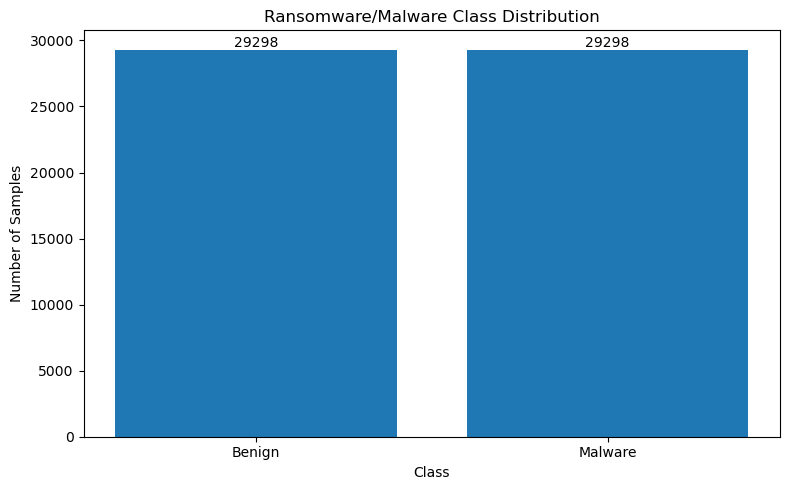

In [ ]:
class_counts = df["Class"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(class_counts.index.astype(str), class_counts.values)

plt.title("Ransomware/Malware Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

for i, value in enumerate(class_counts.values):
    plt.text(i, value, str(value), ha="center", va="bottom")

plt.tight_layout()
plt.show()

In [ ]:
# Remove rows where target is missing
df = df.dropna(subset=["Class"]).copy()

# Numerical features
features = df.select_dtypes(include=np.number).columns.tolist()

print("Features used for ML:")
print(features)

# X = input features
X = df[features].copy()

# y = target
y = df["Class"].copy()

# Handle infinity and missing values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("\nX shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget values:")
print(y.value_counts())

Features used for ML:
['pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.nprocs64bit', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.avg_handles_per_proc', 'handles.nport', 'handles.nfile', 'handles.nevent', 'handles.ndesktop', 'handles.nkey', 'handles.nthread', 'handles.ndirectory', 'handles.nsemaphore', 'handles.ntimer', 'handles.nsection', 'handles.nmutant', 'ldrmodules.not_in_load', 'ldrmodules.not_in_init', 'ldrmodules.not_in_mem', 'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg', 'ldrmodules.not_in_mem_avg', 'malfind.ninjections', 'malfind.commitCharge', 'malfind.protection', 'malfind.uniqueInjections', 'psxview.not_in_pslist', 'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool', 'psxview.not_in_pspcid_list', 'psxview.not_in_csrss_handles', 'psxview.not_in_session', 'psxview.not_in_deskthrd', 'psxview.not_in_pslist_false_avg', 'psxview.not_in_eprocess_pool_false_avg', 'psxview.not_in_ethread_pool_

In [ ]:
malware_count = (df["Class"] == "Malware").sum()
benign_count = (df["Class"] == "Benign").sum()

total_samples = malware_count + benign_count

malware_percentage = malware_count / total_samples * 100
benign_percentage = benign_count / total_samples * 100

print("===== MALWARE PREVALENCE =====")

print("Total Samples:", total_samples)
print("Malware Samples:", malware_count)
print("Benign Samples:", benign_count)

print(f"Malware Percentage: {malware_percentage:.2f}%")
print(f"Benign Percentage: {benign_percentage:.2f}%")

===== MALWARE PREVALENCE =====
Total Samples: 58596
Malware Samples: 29298
Benign Samples: 29298
Malware Percentage: 50.00%
Benign Percentage: 50.00%


In [ ]:
# MALWARE vs BENIGN COMPARISON

# Select only numeric columns
numeric_features = df.select_dtypes(include=np.number).columns.tolist()

# Remove Target from the feature list
numeric_features = [
    col for col in numeric_features
    if col != "Target"
]

# Create separate datasets
malware_data = df[df["Class"] == "Malware"]
benign_data = df[df["Class"] == "Benign"]

# Calculate means safely
malware_mean = malware_data[numeric_features].mean()
benign_mean = benign_data[numeric_features].mean()

# Create comparison table
comparison = pd.DataFrame({
    "Malware Mean": malware_mean,
    "Benign Mean": benign_mean
})

# Calculate difference
comparison["Absolute Difference"] = (
    comparison["Malware Mean"] -
    comparison["Benign Mean"]
).abs()

# Sort by largest difference
comparison = comparison.sort_values(
    "Absolute Difference",
    ascending=False
)

print("===== MALWARE vs BENIGN FEATURE COMPARISON =====")

print(
    comparison.head(20).round(4)
)

===== MALWARE vs BENIGN FEATURE COMPARISON =====
                              Malware Mean  Benign Mean  Absolute Difference
handles.nhandles                 8398.1461   12119.0224            3720.8763
malfind.commitCharge             1928.1233      10.2752            1917.8481
handles.nevent                   2866.2125    4278.6074            1412.3949
dlllist.ndlls                    1539.0891    2082.5218             543.4327
handles.nthread                   721.0086    1136.0116             415.0030
handles.nfile                     748.4508    1049.7882             301.3375
handles.nsection                  171.6803     408.5746             236.8944
handles.nkey                      669.2614     879.2999             210.0385
handles.nsemaphore                610.6364     756.0423             145.4059
handles.nmutant                   250.0155     375.1622             125.1467
pslist.avg_handlers               210.1386     284.8810              74.7423
handles.avg_handles_per_pro

In [ ]:
# CORRELATION WITH MALWARE

# Make a copy of the dataset
corr_df = df.copy()

# Convert all possible feature columns to numeric
numeric_features = []

for column in corr_df.columns:

    # Skip categorical columns
    if column in ["Class", "Category", "Target"]:
        continue

    converted = pd.to_numeric(
        corr_df[column],
        errors="coerce"
    )

    # Keep column if it contains numeric data
    if converted.notna().sum() > 0:
        corr_df[column] = converted
        numeric_features.append(column)

print("Number of numeric features:", len(numeric_features))

print("\nFeatures used:")
print(numeric_features)

# Create a numeric target
corr_df["Malware_Target"] = (
    corr_df["Class"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "benign": 0,
        "malware": 1
    })
)

# Remove rows where target could not be converted
corr_df = corr_df.dropna(
    subset=["Malware_Target"]
)

# Calculate correlation
correlation = corr_df[
    numeric_features + ["Malware_Target"]
].corr()

# Correlation with malware
target_correlation = (
    correlation["Malware_Target"]
    .drop("Malware_Target")
    .sort_values(
        key=lambda x: x.abs(),
        ascending=False
    )
)

print("\n===== FEATURE CORRELATION WITH MALWARE =====")

print(
    target_correlation.round(4)
)

Number of numeric features: 55

Features used:
['pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.nprocs64bit', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.avg_handles_per_proc', 'handles.nport', 'handles.nfile', 'handles.nevent', 'handles.ndesktop', 'handles.nkey', 'handles.nthread', 'handles.ndirectory', 'handles.nsemaphore', 'handles.ntimer', 'handles.nsection', 'handles.nmutant', 'ldrmodules.not_in_load', 'ldrmodules.not_in_init', 'ldrmodules.not_in_mem', 'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg', 'ldrmodules.not_in_mem_avg', 'malfind.ninjections', 'malfind.commitCharge', 'malfind.protection', 'malfind.uniqueInjections', 'psxview.not_in_pslist', 'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool', 'psxview.not_in_pspcid_list', 'psxview.not_in_csrss_handles', 'psxview.not_in_session', 'psxview.not_in_deskthrd', 'psxview.not_in_pslist_false_avg', 'psxview.not_in_eprocess_pool_false_avg', 'psx

In [ ]:
# ==========================================
# TOP 15 CORRELATED FEATURES
# ==========================================

top_corr = target_correlation.head(15)

print("===== TOP 15 FEATURES =====")

print(
    top_corr.round(4)
)

===== TOP 15 FEATURES =====
dlllist.avg_dlls_per_proc         -0.9086
handles.nevent                    -0.8768
handles.nthread                   -0.8725
handles.nmutant                   -0.8551
dlllist.ndlls                     -0.8239
handles.nsection                  -0.8210
pslist.avg_threads                -0.7907
ldrmodules.not_in_load            -0.7875
ldrmodules.not_in_mem             -0.7874
handles.ntimer                    -0.7831
handles.nsemaphore                -0.7691
svcscan.process_services          -0.7637
ldrmodules.not_in_init            -0.7166
svcscan.shared_process_services   -0.7110
handles.nkey                      -0.6982
Name: Malware_Target, dtype: float64


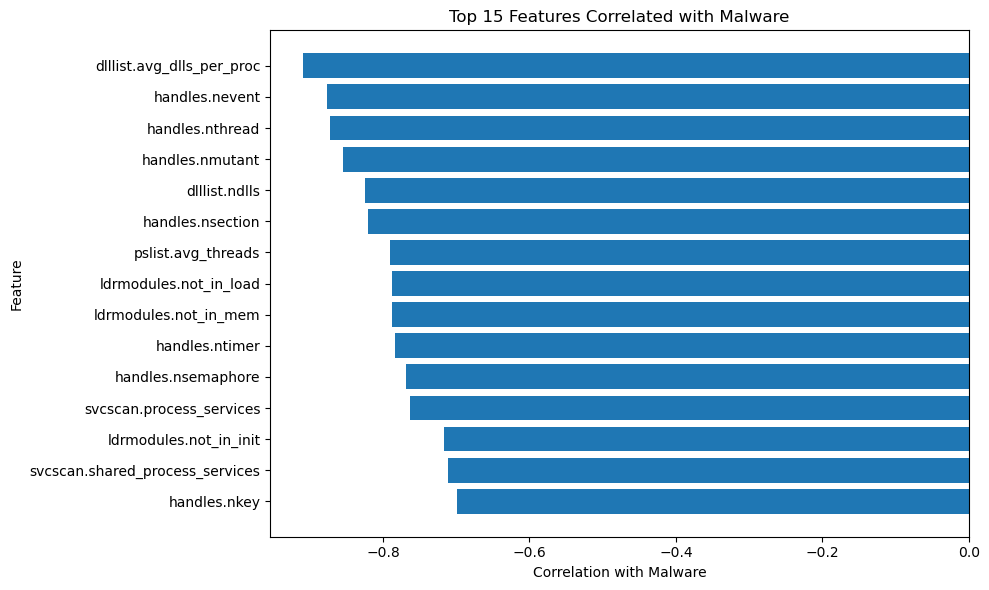

In [ ]:
# CORRELATION VISUALIZATION

plt.figure(figsize=(10, 6))

plt.barh(
    top_corr.index[::-1],
    top_corr.values[::-1]
)

plt.xlabel("Correlation with Malware")
plt.ylabel("Feature")

plt.title(
    "Top 15 Features Correlated with Malware"
)

plt.tight_layout()

plt.show()

Correlation matrix shape:
(56, 56)

===== CORRELATION MATRIX =====
                                        pslist.nproc  pslist.nppid  \
pslist.nproc                                    1.00          0.49   
pslist.nppid                                    0.49          1.00   
pslist.avg_threads                             -0.21         -0.73   
pslist.nprocs64bit                               NaN           NaN   
pslist.avg_handlers                            -0.00         -0.22   
dlllist.ndlls                                   0.57         -0.09   
dlllist.avg_dlls_per_proc                      -0.01         -0.59   
handles.nhandles                                0.21         -0.09   
handles.avg_handles_per_proc                    0.02         -0.16   
handles.nport                                    NaN           NaN   
handles.nfile                                   0.03         -0.01   
handles.nevent                                  0.44         -0.28   
handles.ndesktop       

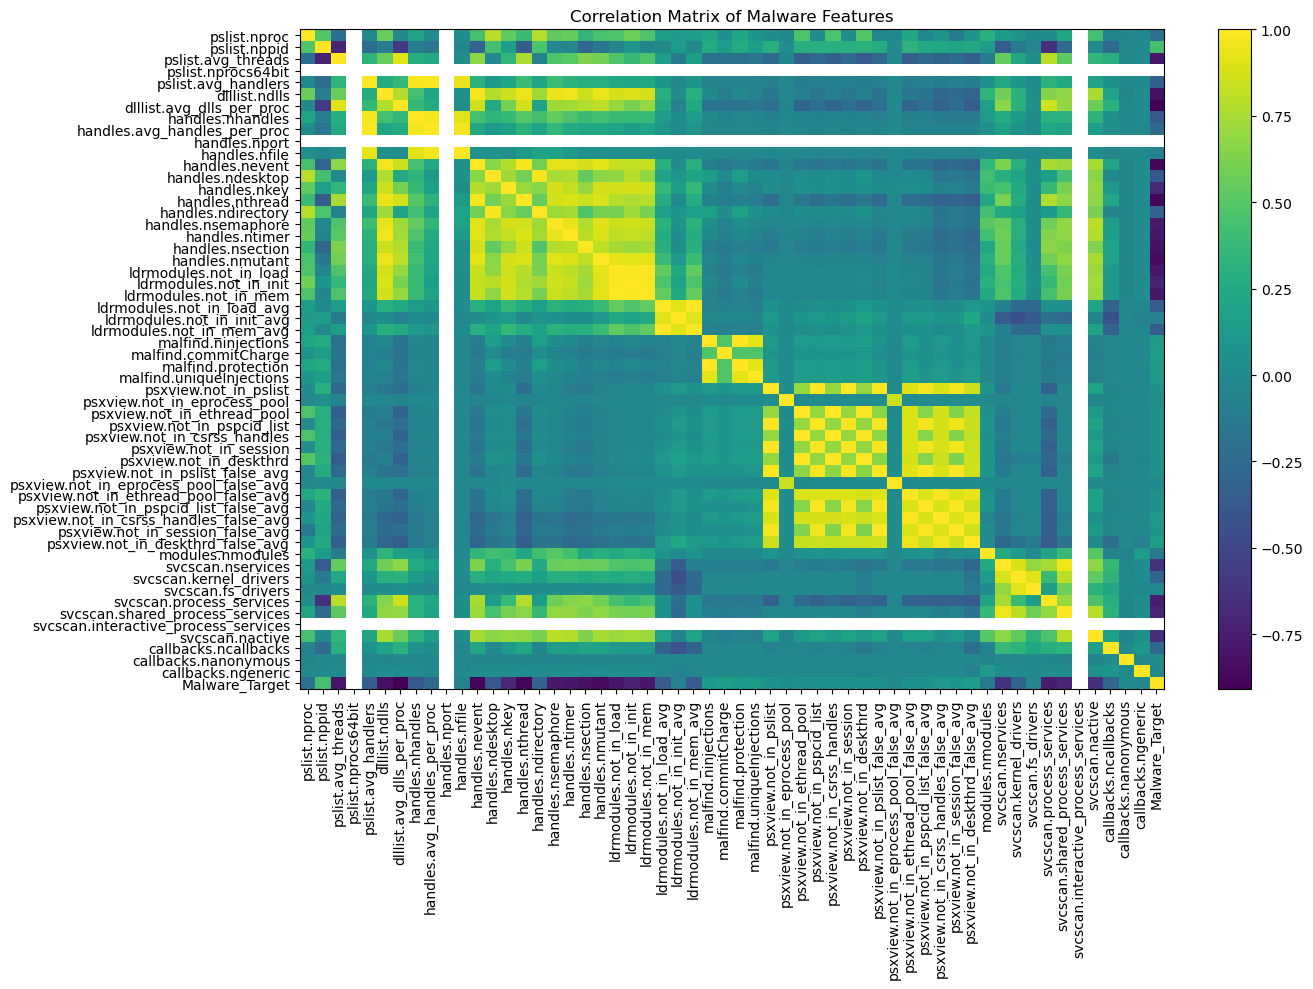

In [ ]:
# CORRELATION MATRIX

# Create correlation matrix
corr_matrix = corr_df[
    numeric_features + ["Malware_Target"]
].corr()

print("Correlation matrix shape:")
print(corr_matrix.shape)

print("\n===== CORRELATION MATRIX =====")
print(corr_matrix.round(2))

plt.figure(figsize=(14, 10))

plt.imshow(
    corr_matrix,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title(
    "Correlation Matrix of Malware Features"
)

plt.tight_layout()

plt.show()

In [ ]:
# MACHINE LEARNING PREPARATION

# Create X using numerical features
X = df[numeric_features].copy()

# Create target
y = (
    df["Class"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "benign": 0,
        "malware": 1
    })
)

# Remove rows with invalid target
valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

# Replace infinity values
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

# Fill missing values with median
X = X.fillna(
    X.median()
)

print("===== MACHINE LEARNING DATA =====")

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing values remaining:")
print(X.isnull().sum().sum())

===== MACHINE LEARNING DATA =====
X shape: (58596, 55)
y shape: (58596,)

Target distribution:
Class
0    29298
1    29298
Name: count, dtype: int64

Missing values remaining:
0


In [ ]:
# TRAIN TEST SPLIT

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("===== DATA SPLIT =====")

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

===== DATA SPLIT =====
Training samples: 46876
Testing samples: 11720

Training target:
Class
0    23438
1    23438
Name: count, dtype: int64

Testing target:
Class
1    5860
0    5860
Name: count, dtype: int64


In [ ]:
#  LOGISTIC REGRESSION

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Train
logistic_model.fit(
    X_train,
    y_train
)

# Test
lr_pred = logistic_model.predict(
    X_test
)

# Probability of malware
lr_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [ ]:
# LOGISTIC REGRESSION TESTING

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

lr_accuracy = accuracy_score(
    y_test,
    lr_pred
)

lr_precision = precision_score(
    y_test,
    lr_pred,
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    lr_pred,
    zero_division=0
)

lr_f1 = f1_score(
    y_test,
    lr_pred,
    zero_division=0
)

lr_auc = roc_auc_score(
    y_test,
    lr_prob
)

print("===== LOGISTIC REGRESSION RESULTS =====")

print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1 Score  : {lr_f1:.4f}")
print(f"ROC-AUC   : {lr_auc:.4f}")

===== LOGISTIC REGRESSION RESULTS =====
Accuracy  : 0.9989
Precision : 0.9986
Recall    : 0.9991
F1 Score  : 0.9989
ROC-AUC   : 1.0000


In [ ]:
# RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Train
rf_model.fit(
    X_train,
    y_train
)

# Test
rf_pred = rf_model.predict(
    X_test
)

# Malware probability
rf_prob = rf_model.predict_proba(
    X_test
)[:, 1]

print("Random Forest training completed.")

Random Forest training completed.


In [ ]:
#  RANDOM FOREST TESTING

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

rf_precision = precision_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_pred,
    zero_division=0
)

rf_auc = roc_auc_score(
    y_test,
    rf_prob
)

print("===== RANDOM FOREST RESULTS =====")

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1 Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_auc:.4f}")

===== RANDOM FOREST RESULTS =====
Accuracy  : 0.9999
Precision : 0.9998
Recall    : 1.0000
F1 Score  : 0.9999
ROC-AUC   : 1.0000


In [ ]:
#  GRADIENT BOOSTING

from sklearn.ensemble import HistGradientBoostingClassifier

gb_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.08,
    random_state=42
)

# Train
gb_model.fit(
    X_train,
    y_train
)

# Test
gb_pred = gb_model.predict(
    X_test
)

# Probability
gb_prob = gb_model.predict_proba(
    X_test
)[:, 1]

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


In [ ]:
# GRADIENT BOOSTING TESTING

gb_accuracy = accuracy_score(
    y_test,
    gb_pred
)

gb_precision = precision_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_recall = recall_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_f1 = f1_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_auc = roc_auc_score(
    y_test,
    gb_prob
)

print("===== GRADIENT BOOSTING RESULTS =====")

print(f"Accuracy  : {gb_accuracy:.4f}")
print(f"Precision : {gb_precision:.4f}")
print(f"Recall    : {gb_recall:.4f}")
print(f"F1 Score  : {gb_f1:.4f}")
print(f"ROC-AUC   : {gb_auc:.4f}")

===== GRADIENT BOOSTING RESULTS =====
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000
ROC-AUC   : 1.0000


In [ ]:
#  MODEL COMPARISON

model_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],

    "Accuracy": [
        lr_accuracy,
        rf_accuracy,
        gb_accuracy
    ],

    "Precision": [
        lr_precision,
        rf_precision,
        gb_precision
    ],

    "Recall": [
        lr_recall,
        rf_recall,
        gb_recall
    ],

    "F1 Score": [
        lr_f1,
        rf_f1,
        gb_f1
    ],

    "ROC-AUC": [
        lr_auc,
        rf_auc,
        gb_auc
    ]
})

print("===== MODEL COMPARISON =====")

print(
    model_results.round(4)
)

===== MODEL COMPARISON =====
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.9989     0.9986  0.9991    0.9989      1.0
1        Random Forest    0.9999     0.9998  1.0000    0.9999      1.0
2    Gradient Boosting    1.0000     1.0000  1.0000    1.0000      1.0


===== CONFUSION MATRIX =====
[[5859    1]
 [   0 5860]]


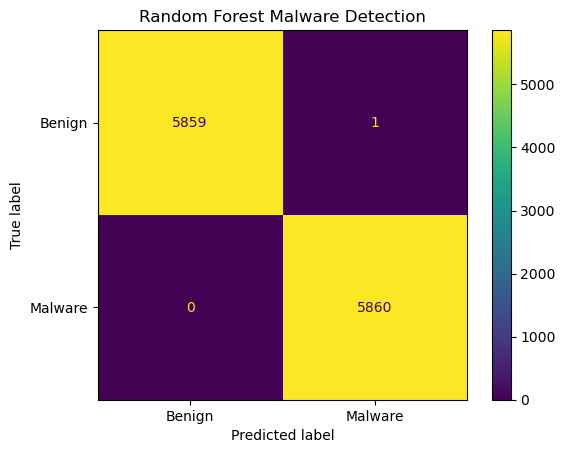

In [ ]:
#  CONFUSION MATRIX

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    rf_pred
)

print("===== CONFUSION MATRIX =====")

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Benign",
        "Malware"
    ]
)

disp.plot()

plt.title(
    "Random Forest Malware Detection"
)

plt.show()

In [ ]:
# FALSE NEGATIVE ANALYSIS

false_negative_mask = (
    (y_test == 1) &
    (rf_pred == 0)
)

false_negative_count = (
    false_negative_mask.sum()
)

actual_malware = (
    y_test == 1
).sum()

false_negative_rate = (
    false_negative_count /
    actual_malware
) * 100

print("===== MISSED MALWARE =====")

print(
    "Actual Malware:",
    actual_malware
)

print(
    "Missed Malware:",
    false_negative_count
)

print(
    f"False Negative Rate: "
    f"{false_negative_rate:.2f}%"
)

===== MISSED MALWARE =====
Actual Malware: 5860
Missed Malware: 0
False Negative Rate: 0.00%


In [ ]:
# MALWARE DETECTION RATE

detected_malware = (
    (y_test == 1) &
    (rf_pred == 1)
).sum()

detection_rate = (
    detected_malware /
    actual_malware
) * 100

print("===== MALWARE DETECTION RATE =====")

print(
    "Actual Malware:",
    actual_malware
)

print(
    "Detected Malware:",
    detected_malware
)

print(
    f"Detection Rate: "
    f"{detection_rate:.2f}%"
)

===== MALWARE DETECTION RATE =====
Actual Malware: 5860
Detected Malware: 5860
Detection Rate: 100.00%


===== TOP 20 IMPORTANT FEATURES =====
                            Feature  Importance
45                svcscan.nservices    0.155087
46           svcscan.kernel_drivers    0.129228
49  svcscan.shared_process_services    0.098599
6         dlllist.avg_dlls_per_proc    0.093911
8      handles.avg_handles_per_proc    0.074304
18                 handles.nsection    0.072630
11                   handles.nevent    0.062618
19                  handles.nmutant    0.059876
4               pslist.avg_handlers    0.049155
5                     dlllist.ndlls    0.036840
16               handles.nsemaphore    0.028128
7                  handles.nhandles    0.024309
14                  handles.nthread    0.022633
13                     handles.nkey    0.021432
20           ldrmodules.not_in_load    0.017775
48         svcscan.process_services    0.010156
17                   handles.ntimer    0.008918
10                    handles.nfile    0.008745
51                  svcscan.nactive    0.008152
22

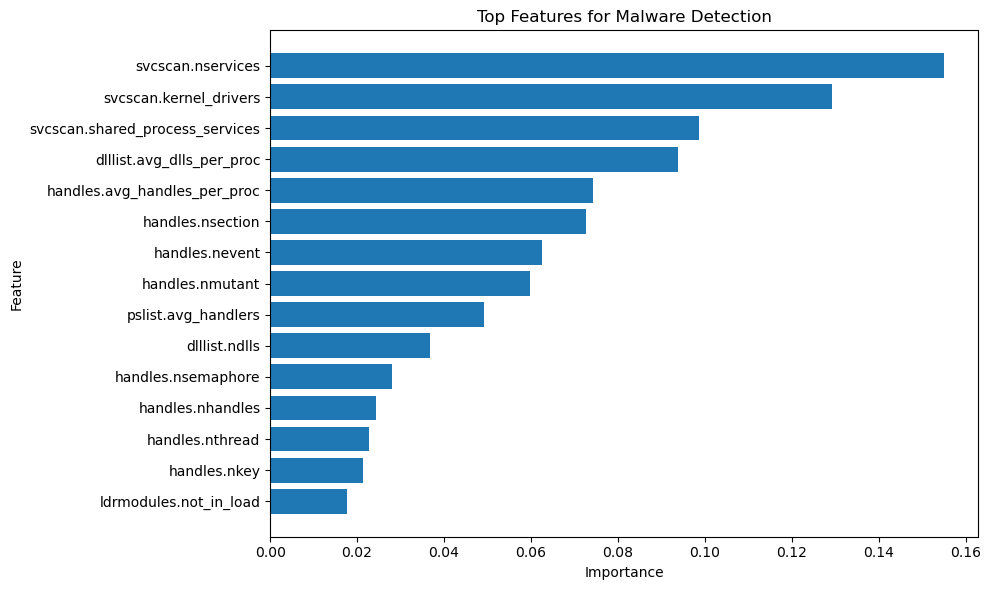

In [ ]:
# RANDOM FOREST FEATURE IMPORTANCE

feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance":
        rf_model.feature_importances_

})

feature_importance = (
    feature_importance
    .sort_values(
        "Importance",
        ascending=False
    )
)

print("===== TOP 20 IMPORTANT FEATURES =====")

print(
    feature_importance.head(20)
)

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Top Features for Malware Detection"
)

plt.tight_layout()

plt.show()

In [ ]:
# STEP 23 — MALWARE RISK SCORE

risk_results = X_test.copy()

risk_results["Actual"] = y_test.values

risk_results["Predicted"] = rf_pred

risk_results["Malware_Probability"] = rf_prob

risk_results["Risk_Category"] = np.select(
    [
        risk_results["Malware_Probability"] >= 0.80,

        risk_results["Malware_Probability"] >= 0.60,

        risk_results["Malware_Probability"] >= 0.40
    ],

    [
        "Very High Risk",
        "High Risk",
        "Medium Risk"
    ],

    default="Low Risk"
)

print(
    risk_results[
        [
            "Actual",
            "Predicted",
            "Malware_Probability",
            "Risk_Category"
        ]
    ].head(20)
)

       Actual  Predicted  Malware_Probability   Risk_Category
50843       1          1                1.000  Very High Risk
37832       1          1                1.000  Very High Risk
6645        0          0                0.000        Low Risk
27932       0          0                0.000        Low Risk
28932       0          0                0.000        Low Risk
17844       0          0                0.000        Low Risk
42206       1          1                1.000  Very High Risk
42186       1          1                1.000  Very High Risk
4612        0          0                0.000        Low Risk
15313       0          0                0.000        Low Risk
43119       1          1                1.000  Very High Risk
37061       1          1                1.000  Very High Risk
15646       0          0                0.000        Low Risk
44301       1          1                0.995  Very High Risk
53795       1          1                1.000  Very High Risk
49072   

In [ ]:
# STEP 24 — MALWARE CATEGORY ANALYSIS

print("===== ALL CATEGORIES =====")

category_counts = (
    df["Category"]
    .value_counts()
)

print(category_counts)

===== ALL CATEGORIES =====
Category
Benign                                                                                     29298
Spyware-Gator-1bdcd3b777965f67678748d2577b119a275aca9aed9549d45e64e692a54a7b5e-1.raw           2
Spyware-Gator-1bfb316482877ee42e5a5078fef44c0eb51bc44c1e88ecbccd02ce4dc4694bd3-2.raw           2
Spyware-Gator-1bfb316482877ee42e5a5078fef44c0eb51bc44c1e88ecbccd02ce4dc4694bd3-10.raw          2
Spyware-Gator-1bfb316482877ee42e5a5078fef44c0eb51bc44c1e88ecbccd02ce4dc4694bd3-1.raw           2
                                                                                           ...  
Spyware-Gator-0b25829d15dc951a44e7652fc6de9d936d7d51f29586d56dbf8fccea419252ac-6.raw           1
Spyware-Gator-0b25829d15dc951a44e7652fc6de9d936d7d51f29586d56dbf8fccea419252ac-5.raw           1
Spyware-Gator-0b25829d15dc951a44e7652fc6de9d936d7d51f29586d56dbf8fccea419252ac-4.raw           1
Spyware-Gator-0b25829d15dc951a44e7652fc6de9d936d7d51f29586d56dbf8fccea419252ac-3.raw       

In [ ]:
# STEP 25 — RANSOMWARE CATEGORY ANALYSIS

# Make sure Category is treated as text
df["Category"] = df["Category"].astype(str)

# Find ransomware-related records
ransomware_df = df[
    df["Category"].str.contains(
        "ransom",
        case=False,
        na=False
    )
].copy()

print("======================================")
print("       RANSOMWARE ANALYSIS")
print("======================================")

print(
    "Total ransomware samples:",
    len(ransomware_df)
)

# Check whether ransomware records exist
if len(ransomware_df) == 0:

    print("\nNo category containing 'ransom' was found.")

    print("\nAvailable categories:")
    print(
        df["Category"]
        .value_counts()
    )

else:

    print("\n===== RANSOMWARE CATEGORIES =====")

    ransom_counts = (
        ransomware_df["Category"]
        .value_counts()
    )

    print(ransom_counts)

    # Plot
    plt.figure(figsize=(12, 7))

    plt.barh(
        ransom_counts.index.astype(str)[::-1],
        ransom_counts.values[::-1]
    )

    plt.xlabel("Number of Samples")
    plt.ylabel("Ransomware Category")

    plt.title(
        "Ransomware Category Distribution"
    )

    plt.tight_layout()
    plt.show()

       RANSOMWARE ANALYSIS
Total ransomware samples: 9791

===== RANSOMWARE CATEGORIES =====
Category
Ransomware-Maze-432dd08b8c8a695fc45398d408261e6d3d61e513ac1161d336c30b1aee533a15-7.raw     2
Ransomware-Maze-172b58ad55b6dd0b871ef11ea09e4f4e9ea4fc2f010773c8507f8571900c36e4-1.raw     2
Ransomware-Pysa-7d3e9848965e09cc7acea44f59c66c28b3c57a5a902a8971b03d24a9634c14b1-2.raw     2
Ransomware-Pysa-7bcbf8f6884549f0eaf03100f105cf419549b8e97f3e264722dac6f4566fcc5c-6.raw     2
Ransomware-Pysa-7bcbf8f6884549f0eaf03100f105cf419549b8e97f3e264722dac6f4566fcc5c-1.raw     2
                                                                                          ..
Ransomware-Maze-53601751dad818fc65e8a2e8b03019cc1789c513830442fcd5e9d417c3546ac5-9.raw     1
Ransomware-Maze-5462c6a2f738998a8f561085e41df1edda1e4a8f4d20b727b47bcf17a859609a-1.raw     1
Ransomware-Maze-5462c6a2f738998a8f561085e41df1edda1e4a8f4d20b727b47bcf17a859609a-10.raw    1
Ransomware-Maze-5462c6a2f738998a8f561085e41df1edda1e4a8f4d20b

In [ ]:
# EXPORT RESULTS

df.to_csv(
    "C:/Users/PALAK THUMBER/Downloads/ransomware_cleaned_dataset.csv",
    index=False
)

model_results.to_csv(
    "C:/Users/PALAK THUMBER/Downloads/ransomware_model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "C:/Users/PALAK THUMBER/Downloads/ransomware_feature_importance.csv",
    index=False
)

risk_results.to_csv(
    "C:/Users/PALAK THUMBER/Downloads/ransomware_risk_predictions.csv",
    index=False
)

ransomware_df.to_csv(
    "C:/Users/PALAK THUMBER/Downloads/ransomware_specific_analysis.csv",
    index=False
)

print("================================")
print("ALL RESULTS EXPORTED SUCCESSFULLY")
print("================================")